In [37]:
import pandas as pd
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score

data = pd.read_csv("data_grupp_13.csv") # Läser in csv filen
X = data.drop(columns=["target"]) # Sätter vad x är, d.v.s. alla kolumner utom target
y = data["target"] # Vad y eller målvariabeln är, d.v.s. target kolumnen

modell = AdaBoostClassifier()
modell.fit(X, y)

# 4. Utvärdera träffsäkerhet och se vilka kolumner som väger tyngst
gissningar = modell.predict(X)
print("Träffsäkerhet:", accuracy_score(y, gissningar))

for kolumn, vikt in zip(X.columns, modell.feature_importances_):
    print(f"{kolumn}: {vikt:.2f}")

Träffsäkerhet: 1.0
besok_per_manad: 0.09
snittorder_kr: 0.49
tid_pa_sajt_sek: 0.12
returgrad: 0.14
kundtjanst_arenden: 0.05
rabattkod_andel: 0.11


In [38]:
import pandas as pd
import numpy as np
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import train_test_split

data = pd.read_csv("data_grupp_13.csv") # Läser in csv filen
X = data.drop(columns=["target"]) # Sätter vad x är, d.v.s. alla kolumner utom target
y = data["target"] # Vad y eller målvariabeln är, d.v.s. target kolumnen

train_X, test_X, train_y, test_y = train_test_split(X, y, test_size=0.2, random_state=42)

clf = AdaBoostClassifier(random_state=42)
clf.fit(train_X, train_y)
clf.score(test_X, test_y)
clf.score(train_X, train_y)

1.0

                precision    recall  f1-score   support

    Fyndjagare       1.00      1.00      1.00        80
Lojal_stamkund       0.99      1.00      0.99        80
Risk_for_churn       1.00      0.99      0.99        80

      accuracy                           1.00       240
     macro avg       1.00      1.00      1.00       240
  weighted avg       1.00      1.00      1.00       240



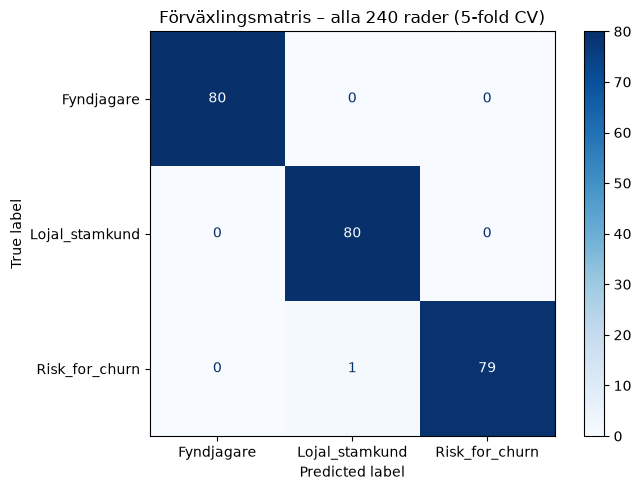

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Läs in all data (240 rader, 6 egenskaper)
df = pd.read_csv("data_grupp_13.csv")
X = df.drop(columns=["target"])
y = df["target"]

modell = AdaBoostClassifier()

# 2. Låt modellen gissa på alla 240 rader via 5-delad korsvalidering
gissningar_all_data = cross_val_predict(modell, X, y, cv=5)

# 3. Skriv ut rapport och rita förväxlingsmatris för samtliga 240 rader
print(classification_report(y, gissningar_all_data, zero_division=0))

cm = confusion_matrix(y, gissningar_all_data, labels=sorted(y.unique()))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=sorted(y.unique()))

fig, ax = plt.subplots(figsize=(7, 5))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Förväxlingsmatris – alla 240 rader (5-fold CV)")
plt.tight_layout()
plt.show()